# Module 4 - Machine Learning Fundamentals
**What this module covers:** supervised 4-class classification of accident `Severity` with **Decision Tree**
(added in this project), **Random Forest** and **Logistic Regression** (both adapted from the upstream MLlib code),
a scikit-learn `Pipeline` + `ColumnTransformer`, stratified 80/20 split, class-imbalance handling, randomized
hyper-parameter search, evaluation (accuracy, macro/weighted F1, per-class P/R/F1, normalized confusion matrices,
ROC-AUC one-vs-rest, 5-fold CV), feature importance, coefficients and a tree plot.

**Project task satisfied here:** *ML: Decision Tree, Random Forest, Logistic Regression.*

**Headline metric:** macro-F1 (every severity level counts equally), reported together with accuracy.

In [1]:
import sys, time, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import randint, loguniform
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from src import utils as U, viz as V, modeling as M

V.apply_style()
FIG, MET = U.FIGURES, U.METRICS
RS = U.RANDOM_STATE
df = pd.read_parquet(U.CLEAN_PARQUET)
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| interpreter:", Path(sys.executable).parent.parent.name)
import sklearn; print("scikit-learn", sklearn.__version__)

Python 3.14.2 | pandas 3.1.0 | interpreter: .venv
scikit-learn 1.9.1


## 1. Features and leakage control
| Used | Not used (and why) |
|---|---|
| Start_Lat, Start_Lng, State, City (frequency + top-30 one-hot) | `End_Time`, `Duration_min`: known only after the accident is cleared (leakage) |
| Temperature, Humidity, Pressure, Visibility, Wind speed, Precipitation, WeatherGroup, Wind_Direction | `Distance(mi)`: length of the affected road, measured after the event - **tested both ways below** |
| Hour, DayOfWeek, Month, IsWeekend, IsRushHour, DayNight | `Year`: data-collection artefact (severe share 34% in 2016 -> 3% in 2023, Module 2) |
| 12 road-feature flags + RoadFeatureCount | `Source`: data-provider artefact; `ID`; free text (`Description` dropped in Module 1) |

In [2]:
y = df["Severity"]
X = df[M.feature_columns(with_distance=True)]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
split = pd.DataFrame({"train": y_train.value_counts().sort_index(), "test": y_test.value_counts().sort_index()})
split["train_pct"] = (100 * split["train"] / split["train"].sum()).round(2)
split["test_pct"] = (100 * split["test"] / split["test"].sum()).round(2)
print(f"Train rows: {len(X_train):,}  Test rows: {len(X_test):,}")
FEATS = {False: M.feature_columns(False), True: M.feature_columns(True)}
split

Train rows: 319,664  Test rows: 79,917


,train,test,train_pct,test_pct
Severity,,,,
1,2786,696,0.87,0.87
2,254629,63658,79.66,79.66
3,53785,13447,16.83,16.83
4,8464,2116,2.65,2.65


## 2. Majority-class baseline (from upstream)

In [3]:
maj = y_train.mode().iloc[0]
baseline = M.evaluate(y_test, np.full(len(y_test), maj))
print(f"Always predict Severity {maj}: accuracy={baseline['accuracy']}, macro-F1={baseline['macro_f1']}")

Always predict Severity 2: accuracy=0.7966, macro-F1=0.2217


## 3. Hyper-parameter search (RandomizedSearchCV, 3-fold, scoring = macro-F1)
Run on the **full training set** (320k rows; fast enough on this laptop, so no subsample was needed), without
Distance, with `class_weight="balanced"` for all three models.

In [4]:
cv3 = StratifiedKFold(3, shuffle=True, random_state=RS)
spaces = {
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=RS), False,
                      {"model__max_depth": randint(6, 31), "model__min_samples_leaf": randint(1, 101),
                       "model__criterion": ["gini", "entropy"]}, 15, -1),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RS), False,
                      {"model__n_estimators": [100, 150, 200], "model__max_depth": randint(12, 31),
                       "model__min_samples_leaf": randint(1, 21), "model__max_features": ["sqrt", 0.3]}, 8, 1),
    "Logistic Regression": (LogisticRegression(class_weight="balanced", max_iter=1000), True,
                            {"model__C": loguniform(1e-3, 1e2)}, 6, -1),
}
best_params, search_rows = {}, []
for name, (est, scale, space, n_iter, n_jobs) in spaces.items():
    t0 = time.time()
    rs = RandomizedSearchCV(M.make_pipeline(est, False, scale), space, n_iter=n_iter, scoring="f1_macro", cv=cv3,
                            random_state=RS, n_jobs=n_jobs, refit=False)
    rs.fit(X_train[FEATS[False]], y_train)
    best_params[name] = {k.replace("model__", ""): v for k, v in rs.best_params_.items()}
    search_rows.append({"model": name, "n_iter": n_iter, "best_cv_macro_f1": round(rs.best_score_, 4),
                        "best_params": json.dumps(best_params[name], default=str), "search_seconds": round(time.time() - t0, 1)})
    print(f"{name}: best 3-fold macro-F1={rs.best_score_:.4f}  params={best_params[name]}  ({time.time() - t0:.0f} s)")
search = pd.DataFrame(search_rows); search.to_csv(MET / "hyperparameter_search.csv", index=False)
search

Decision Tree: best 3-fold macro-F1=0.3435  params={'criterion': 'entropy', 'max_depth': 26, 'min_samples_leaf': 2}  (54 s)


Random Forest: best 3-fold macro-F1=0.3753  params={'max_depth': 17, 'max_features': 0.3, 'min_samples_leaf': 1, 'n_estimators': 150}  (287 s)


Logistic Regression: best 3-fold macro-F1=0.2587  params={'C': np.float64(56.69849511478853)}  (73 s)


,model,n_iter,best_cv_macro_f1,best_params,search_seconds
0,Decision Tree,15,0.3435,"{""criterion"": ""entropy"", ""max_depth"": 26, ""min...",54.1
1,Random Forest,8,0.3753,"{""max_depth"": 17, ""max_features"": 0.3, ""min_sa...",286.7
2,Logistic Regression,6,0.2587,"{""C"": 56.69849511478853}",73.4


## 4. Fit tuned models - without and with `Distance(mi)`

In [5]:
def build(name, with_distance):
    params = {k: (v.item() if hasattr(v, "item") else v) for k, v in best_params[name].items()}
    if name == "Decision Tree":
        est, scale = DecisionTreeClassifier(class_weight="balanced", random_state=RS, **params), False
    elif name == "Random Forest":
        est, scale = RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RS, **params), False
    else:
        est, scale = LogisticRegression(class_weight="balanced", max_iter=1000, **params), True
    return M.make_pipeline(est, with_distance, scale)

results, fitted, preds = [], {}, {}
for with_d in (False, True):
    for name in spaces:
        t0 = time.time()
        pipe = build(name, with_d).fit(X_train[FEATS[with_d]], y_train)
        secs = time.time() - t0
        pr = pipe.predict(X_test[FEATS[with_d]]); pp = pipe.predict_proba(X_test[FEATS[with_d]])
        ev = M.evaluate(y_test, pr, pp)
        results.append({"model": name, "distance_feature": "with" if with_d else "without", "class_weight": "balanced",
                        "train_seconds": round(secs, 1), **ev})
        fitted[(name, with_d)] = pipe; preds[(name, with_d)] = pr
        print(f"{name:20s} {'with' if with_d else 'without':7s} Distance: acc={ev['accuracy']:.4f} macro-F1={ev['macro_f1']:.4f} "
              f"ROC-AUC={ev['roc_auc_ovr_macro']:.4f} ({secs:.0f} s)")
results.append({"model": "Majority baseline", "distance_feature": "-", "class_weight": "-", "train_seconds": 0, **baseline})
comp = pd.DataFrame(results)
comp.to_csv(MET / "model_comparison.csv", index=False)
cols = ["model", "distance_feature", "accuracy", "macro_f1", "weighted_f1", "balanced_accuracy", "roc_auc_ovr_macro",
        "recall_sev1", "recall_sev2", "recall_sev3", "recall_sev4", "train_seconds"]
comp[cols]

Decision Tree        without Distance: acc=0.6490 macro-F1=0.3530 ROC-AUC=0.6272 (16 s)


Random Forest        without Distance: acc=0.5946 macro-F1=0.3751 ROC-AUC=0.8096 (25 s)


Logistic Regression  without Distance: acc=0.3747 macro-F1=0.2611 ROC-AUC=0.7352 (33 s)


Decision Tree        with    Distance: acc=0.7028 macro-F1=0.4138 ROC-AUC=0.6844 (15 s)


Random Forest        with    Distance: acc=0.6313 macro-F1=0.4206 ROC-AUC=0.8721 (24 s)


Logistic Regression  with    Distance: acc=0.3901 macro-F1=0.2736 ROC-AUC=0.7500 (30 s)


,model,distance_feature,accuracy,macro_f1,weighted_f1,balanced_accuracy,roc_auc_ovr_macro,recall_sev1,recall_sev2,recall_sev3,recall_sev4,train_seconds
0,Decision Tree,without,0.6490,0.3530,0.6852,0.4265,0.6272,0.3075,0.7057,0.4643,0.2287,15.6
1,Random Forest,without,0.5946,0.3751,0.6525,0.5902,0.8096,0.6537,0.5867,0.6482,0.4721,25.2
2,Logistic Regression,without,0.3747,0.2611,0.4606,0.5294,0.7352,0.7055,0.3429,0.4729,0.5964,32.7
3,Decision Tree,with,0.7028,0.4138,0.7322,0.5086,0.6844,0.3966,0.7430,0.5915,0.3034,15.0
4,Random Forest,with,0.6313,0.4206,0.6881,0.6946,0.8721,0.7457,0.6054,0.7392,0.6881,24.3
5,Logistic Regression,with,0.3901,0.2736,0.4740,0.5591,0.7500,0.7543,0.3526,0.5131,0.6163,30.0
6,Majority baseline,-,0.7966,0.2217,0.7063,0.2500,NaN,0.0000,1.0000,0.0000,0.0000,0.0


## 5. Class-weighting scheme: inverse ("balanced") vs square root (upstream comparison, re-tested)

In [6]:
wrows = []
sw = M.sqrt_balanced_weights(y_train)
for name in ["Logistic Regression", "Random Forest", "Decision Tree"]:
    pipe = build(name, False)
    pipe.set_params(model__class_weight=None)
    pipe.fit(X_train[FEATS[False]], y_train, model__sample_weight=sw)
    ev = M.evaluate(y_test, pipe.predict(X_test[FEATS[False]]), pipe.predict_proba(X_test[FEATS[False]]))
    inv = comp[(comp.model == name) & (comp.distance_feature == "without")].iloc[0]
    for scheme, e in (("inverse (balanced)", inv), ("sqrt", ev)):
        wrows.append({"model": name, "weights": scheme, "accuracy": e["accuracy"], "macro_f1": e["macro_f1"],
                      "weighted_f1": e["weighted_f1"], "recall_sev1": e["recall_sev1"], "recall_sev4": e["recall_sev4"]})
wcomp = pd.DataFrame(wrows); wcomp.to_csv(MET / "class_weight_comparison.csv", index=False)
wcomp

,model,weights,accuracy,macro_f1,weighted_f1,recall_sev1,recall_sev4
0,Logistic Regression,inverse (balanced),0.3747,0.2611,0.4606,0.7055,0.5964
1,Logistic Regression,sqrt,0.7681,0.3504,0.7463,0.1279,0.0681
2,Random Forest,inverse (balanced),0.5946,0.3751,0.6525,0.6537,0.4721
3,Random Forest,sqrt,0.7984,0.4262,0.7839,0.1322,0.1493
4,Decision Tree,inverse (balanced),0.6490,0.3530,0.6852,0.3075,0.2287
5,Decision Tree,sqrt,0.7007,0.3703,0.7187,0.2126,0.1805


## 6. Best model (highest macro-F1, without Distance = strictly leakage-free)

In [7]:
main = comp[comp.distance_feature == "without"].sort_values("macro_f1", ascending=False)
best_name = main.iloc[0]["model"]
best_pipe = fitted[(best_name, False)]
print(f"Best model: {best_name}  macro-F1={main.iloc[0]['macro_f1']}  accuracy={main.iloc[0]['accuracy']}")
print(classification_report(y_test, preds[(best_name, False)], digits=4))
dist = comp[comp.model == best_name].set_index("distance_feature")
print(f"Adding Distance changes macro-F1 of {best_name} from {dist.loc['without', 'macro_f1']} to {dist.loc['with', 'macro_f1']}")

Best model: Random Forest  macro-F1=0.3751  accuracy=0.5946
              precision    recall  f1-score   support

           1     0.0828    0.6537    0.1470       696
           2     0.9159    0.5867    0.7152     63658
           3     0.3512    0.6482    0.4556     13447
           4     0.1131    0.4721    0.1825      2116

    accuracy                         0.5946     79917
   macro avg     0.3658    0.5902    0.3751     79917
weighted avg     0.7924    0.5946    0.6525     79917

Adding Distance changes macro-F1 of Random Forest from 0.3751 to 0.4206


### 6.1 5-fold stratified cross-validation of the best model (full training set)

In [8]:
t0 = time.time()
cvres = cross_validate(build(best_name, False), X_train[FEATS[False]], y_train,
                       cv=StratifiedKFold(5, shuffle=True, random_state=RS), scoring=["f1_macro", "accuracy"], n_jobs=1)
cv_summary = {"folds": 5, "macro_f1_mean": round(float(cvres["test_f1_macro"].mean()), 4), "macro_f1_std": round(float(cvres["test_f1_macro"].std()), 4),
              "accuracy_mean": round(float(cvres["test_accuracy"].mean()), 4), "accuracy_std": round(float(cvres["test_accuracy"].std()), 4),
              "macro_f1_per_fold": [round(float(v), 4) for v in cvres["test_f1_macro"]]}
print(cv_summary, f"({time.time() - t0:.0f} s)")

{'folds': 5, 'macro_f1_mean': 0.3738, 'macro_f1_std': 0.0011, 'accuracy_mean': 0.6004, 'accuracy_std': 0.0025, 'macro_f1_per_fold': [0.3719, 0.3752, 0.3734, 0.3742, 0.374]} (105 s)


In [9]:
bm = main.iloc[0]
best_json = {"best_model": best_name, "selection": "highest test macro-F1, without Distance(mi)",
             "params": {k: (v.item() if hasattr(v, "item") else v) for k, v in best_params[best_name].items()},
             "test": {k: bm[k] for k in ["accuracy", "macro_f1", "weighted_f1", "balanced_accuracy", "roc_auc_ovr_macro"]},
             "test_with_distance": {k: dist.loc["with", k] for k in ["accuracy", "macro_f1", "roc_auc_ovr_macro"]},
             "cv_5fold": cv_summary, "baseline_majority": {k: baseline[k] for k in ["accuracy", "macro_f1"]},
             "train_rows": len(X_train), "test_rows": len(X_test), "random_state": RS,
             "features": FEATS[False]}
U.save_json(best_json, MET / "best_model.json")
U.MODELS.mkdir(exist_ok=True)
mpath = U.MODELS / "best_model.joblib"
joblib.dump(best_pipe, mpath, compress=3)
print(f"Saved {mpath.relative_to(ROOT)} ({mpath.stat().st_size / 1e6:.1f} MB)")

Saved models\best_model.joblib (64.8 MB)


## 7. Normalized confusion matrices (rows = actual, without Distance)

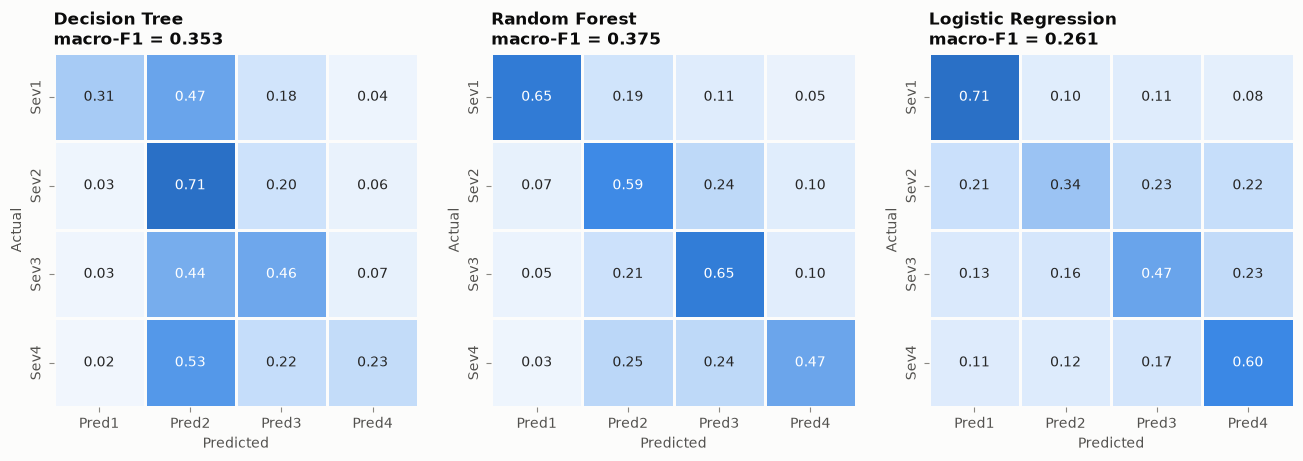

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for a, name in zip(axes, spaces):
    cm = M.normalized_confusion(y_test, preds[(name, False)])
    cm.round(4).to_csv(MET / f"confusion_{name.lower().replace(' ', '_')}.csv")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap=V.SEQ_CMAP, vmin=0, vmax=1, ax=a, cbar=False, linewidths=1, linecolor=V.SURFACE)
    mf = comp[(comp.model == name) & (comp.distance_feature == "without")]["macro_f1"].iloc[0]
    a.set(title=f"{name}\nmacro-F1 = {mf:.3f}", xlabel="Predicted", ylabel="Actual"); a.grid(False)
V.save(fig, FIG / "ml_confusion_matrices.png")

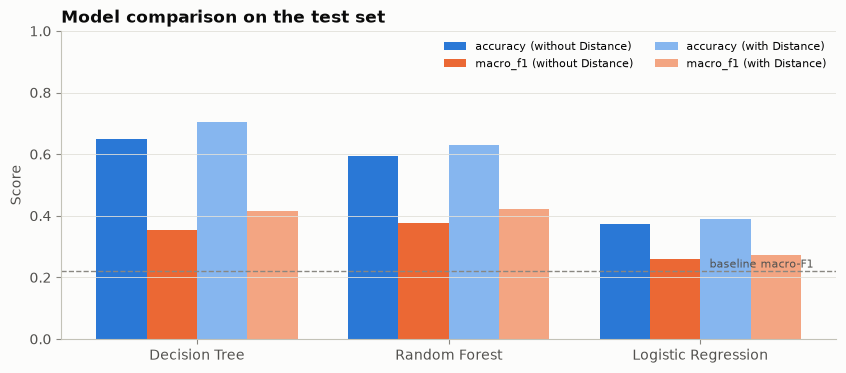

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
m2 = comp[comp.model != "Majority baseline"]
names = list(spaces); x = np.arange(len(names)); w = 0.2
for i, (metric, d, col) in enumerate([("accuracy", "without", V.CATEGORICAL[0]), ("macro_f1", "without", V.CATEGORICAL[1]),
                                      ("accuracy", "with", "#86b6ef"), ("macro_f1", "with", "#f3a582")]):
    vals = [m2[(m2.model == n) & (m2.distance_feature == d)][metric].iloc[0] for n in names]
    ax.bar(x + (i - 1.5) * w, vals, w, color=col, label=f"{metric} ({d} Distance)")
ax.axhline(baseline["macro_f1"], color=V.MUTED, ls="--", lw=1); ax.text(2.45, baseline["macro_f1"] + 0.01, "baseline macro-F1", fontsize=8, color=V.INK2, ha="right")
ax.set_xticks(x); ax.set_xticklabels(names); ax.set(title="Model comparison on the test set", ylabel="Score", ylim=(0, 1))
ax.legend(ncol=2, fontsize=8, loc="upper right")
V.save(fig, FIG / "ml_model_comparison.png")

## 8. Interpretation
### 8.1 Random Forest feature importance (impurity-based, top 20)

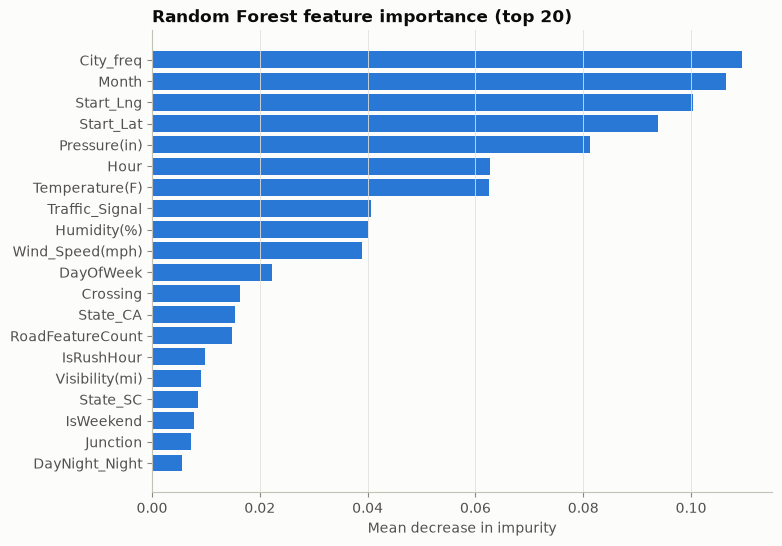

City_freq          0.1095
Month              0.1065
Start_Lng          0.1003
Start_Lat          0.0939
Pressure(in)       0.0812
Hour               0.0626
Temperature(F)     0.0625
Traffic_Signal     0.0407
Humidity(%)        0.0400
Wind_Speed(mph)    0.0389
dtype: float64

In [12]:
rf = fitted[("Random Forest", False)]
fn = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=fn).sort_values(ascending=False)
imp.round(5).rename("importance").to_csv(MET / "rf_feature_importance.csv", header=True)
fig, ax = plt.subplots(figsize=(8, 6))
top = imp.head(20)[::-1]
ax.barh(top.index, top.values, color=V.PRIMARY); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set(title="Random Forest feature importance (top 20)", xlabel="Mean decrease in impurity")
V.save(fig, FIG / "ml_rf_feature_importance.png")
imp.head(10).round(4)

### 8.2 Logistic Regression coefficients (standardized numeric features)

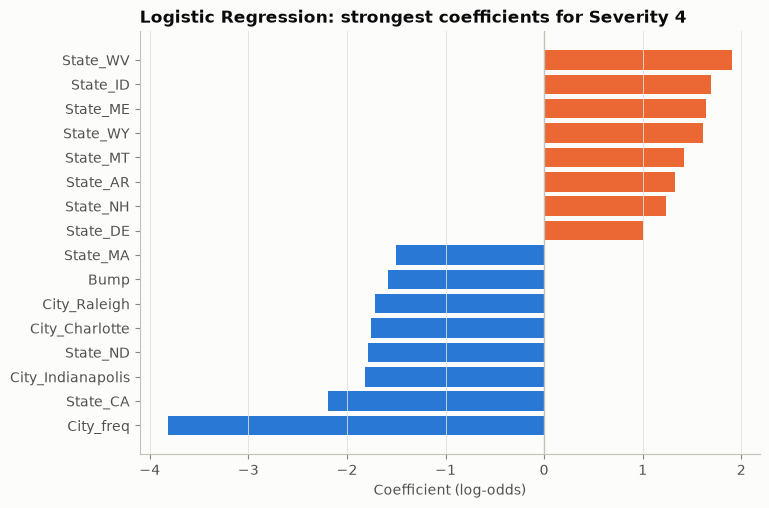

City_freq           -3.816
State_CA            -2.194
City_Indianapolis   -1.821
State_ND            -1.782
City_Charlotte      -1.755
City_Raleigh        -1.716
Bump                -1.584
State_MA            -1.505
State_DE             1.001
State_NH             1.240
State_AR             1.326
State_MT             1.422
State_WY             1.614
State_ME             1.645
State_ID             1.693
State_WV             1.901
Name: Sev4, dtype: float64

In [13]:
lr = fitted[("Logistic Regression", False)]
coef = pd.DataFrame(lr.named_steps["model"].coef_.T, index=lr.named_steps["prep"].get_feature_names_out(),
                    columns=[f"Sev{c}" for c in lr.named_steps["model"].classes_])
coef.round(4).to_csv(MET / "lr_coefficients.csv")
top4 = coef["Sev4"].sort_values()
sel = pd.concat([top4.head(8), top4.tail(8)])
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(sel.index, sel.values, color=[V.CATEGORICAL[0] if v < 0 else V.CATEGORICAL[1] for v in sel.values])
ax.axvline(0, color=V.AXIS, lw=1); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set(title="Logistic Regression: strongest coefficients for Severity 4", xlabel="Coefficient (log-odds)")
V.save(fig, FIG / "ml_lr_coefficients.png")
sel.round(3)

### 8.3 Decision Tree - top 3 levels

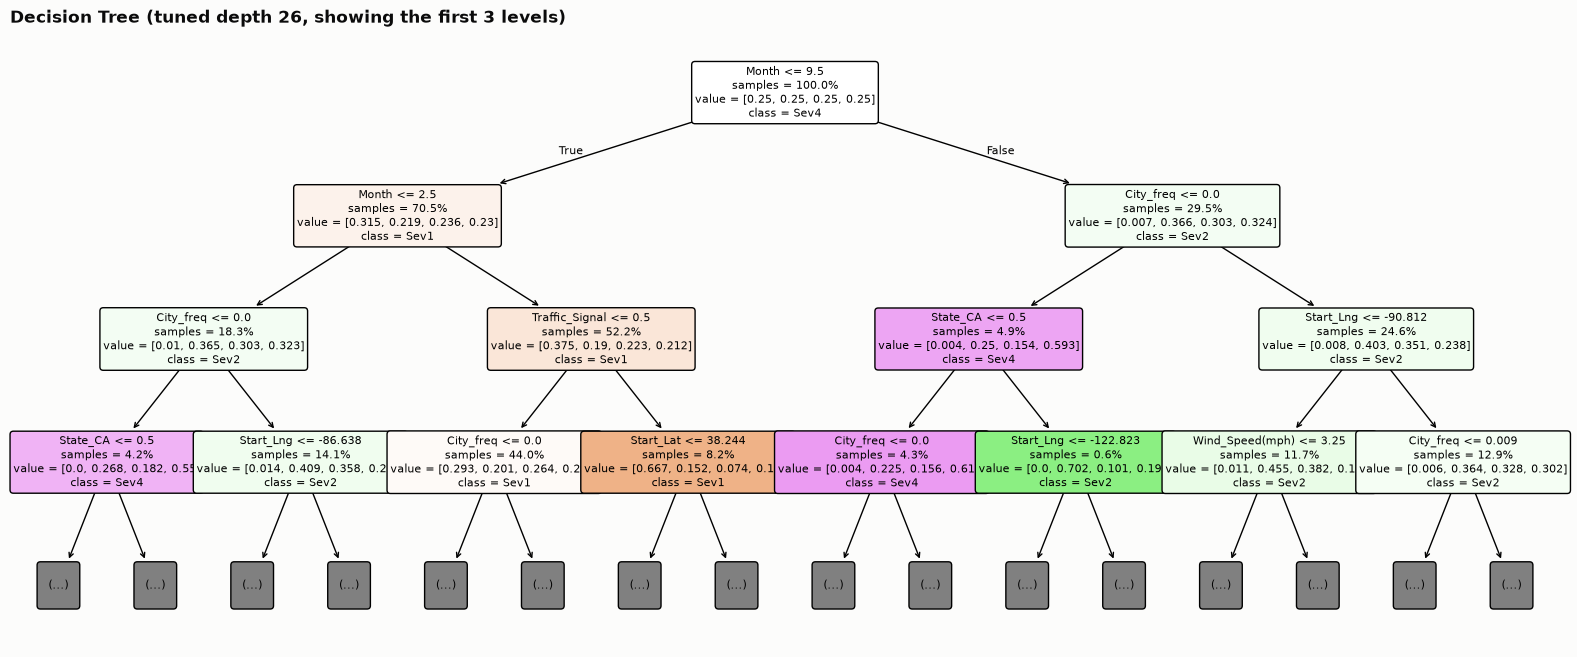

In [14]:
dt = fitted[("Decision Tree", False)]
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(dt.named_steps["model"], max_depth=3, feature_names=dt.named_steps["prep"].get_feature_names_out(),
          class_names=[f"Sev{c}" for c in dt.named_steps["model"].classes_], filled=True, impurity=False,
          proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title(f"Decision Tree (tuned depth {dt.named_steps['model'].get_depth()}, showing the first 3 levels)")
V.save(fig, FIG / "ml_decision_tree.png")

In [15]:
r = {n: comp[(comp.model == n) & (comp.distance_feature == "without")].iloc[0] for n in spaces}
wl = wcomp.set_index(["model", "weights"])
summary = {
    "best": f"{best_name} has the best macro-F1 ({r[best_name]['macro_f1']:.3f}, accuracy {r[best_name]['accuracy']:.3f}) vs the majority "
            f"baseline ({baseline['macro_f1']:.3f} macro-F1, {baseline['accuracy']:.3f} accuracy).",
    "distance": f"Adding Distance(mi) changes {best_name}'s macro-F1 from {dist.loc['without', 'macro_f1']:.3f} to {dist.loc['with', 'macro_f1']:.3f}.",
    "weights": f"For Logistic Regression, sqrt weights give accuracy {wl.loc[('Logistic Regression', 'sqrt'), 'accuracy']:.3f} / macro-F1 "
               f"{wl.loc[('Logistic Regression', 'sqrt'), 'macro_f1']:.3f} vs inverse {wl.loc[('Logistic Regression', 'inverse (balanced)'), 'accuracy']:.3f} / "
               f"{wl.loc[('Logistic Regression', 'inverse (balanced)'), 'macro_f1']:.3f}.",
    "top_feature": f"Most important Random Forest feature: {imp.index[0]} ({imp.iloc[0]:.3f}), then {imp.index[1]} ({imp.iloc[1]:.3f}).",
    "cv": f"5-fold CV macro-F1 of {best_name}: {cv_summary['macro_f1_mean']:.3f} +/- {cv_summary['macro_f1_std']:.3f}.",
}
U.save_json(summary, MET / "ml_insights.json")
for v in summary.values(): print("-", v)

- Random Forest has the best macro-F1 (0.375, accuracy 0.595) vs the majority baseline (0.222 macro-F1, 0.797 accuracy).
- Adding Distance(mi) changes Random Forest's macro-F1 from 0.375 to 0.421.
- For Logistic Regression, sqrt weights give accuracy 0.768 / macro-F1 0.350 vs inverse 0.375 / 0.261.
- Most important Random Forest feature: City_freq (0.110), then Month (0.106).
- 5-fold CV macro-F1 of Random Forest: 0.374 +/- 0.001.


## 9. Conclusions, limitations and real-world use
* **Conclusions** - see the printed summary above (generated from `model_comparison.csv`,
  `class_weight_comparison.csv`, `best_model.json`, `rf_feature_importance.csv`). Tree ensembles use location
  and road context far better than a linear model; class weighting trades accuracy for recall of the rare
  Severity 1 and 4 classes.
* **Limitations** - Severity reflects traffic delay, not injury; labels depend on the data provider (`Source`) and
  the collection period; no traffic-volume, speed-limit or road-class data; a random (not time-based) split, so
  performance on future years may be lower; the model was trained on a 5.18% stratified sample.
* **Real-world use** - ranking incoming reports by probability of a high-impact (3-4) accident to prioritise
  traffic-management response, and flagging locations / conditions where high-impact accidents are more likely.
  It should support, not replace, human dispatch decisions.